<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/PCA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from sklearn.datasets import load_wine
import pandas as pd

wine = load_wine()

X = pd.DataFrame(
    wine.data,
    columns=wine.feature_names
)

y = wine.target

print(X.shape)
X.head()

(178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print(X_scaled.shape)

(178, 13)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA()

X_pca = pca.fit_transform(X_scaled)

X_pca.shape

(178, 13)

In [ ]:
explained_variance = pca.explained_variance_ratio_

for i, variance in enumerate(explained_variance):
    print(f"PC{i+1}: {variance:.4f}")

PC1: 0.3620
PC2: 0.1921
PC3: 0.1112
PC4: 0.0707
PC5: 0.0656
PC6: 0.0494
PC7: 0.0424
PC8: 0.0268
PC9: 0.0222
PC10: 0.0193
PC11: 0.0174
PC12: 0.0130
PC13: 0.0080


In [ ]:
import numpy as np

cumulative_variance = np.cumsum(explained_variance)

print(cumulative_variance)

[0.36198848 0.55406338 0.66529969 0.73598999 0.80162293 0.85098116
 0.89336795 0.92017544 0.94239698 0.96169717 0.97906553 0.99204785
 1.        ]


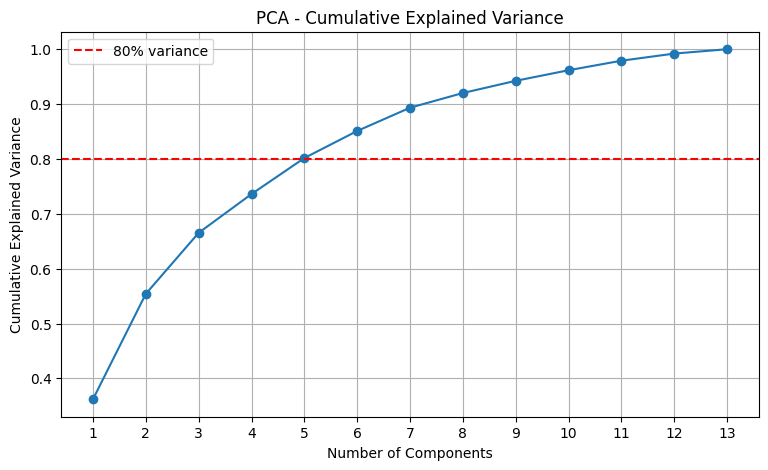

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o'
)

plt.axhline(y=0.80, color='red', linestyle='--',
            label='80% variance')

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance")
plt.xticks(range(1, 14))
plt.grid()
plt.legend()
plt.show()

In [ ]:
pca = PCA(n_components=0.80)

X_reduced = pca.fit_transform(X_scaled)

print(X_reduced.shape)
print(pca.n_components_)

(178, 5)
5


In [ ]:
from sklearn.decomposition import PCA

pca_2d = PCA(n_components=2)

X_2d = pca_2d.fit_transform(X_scaled)

print(X_2d.shape)

(178, 2)


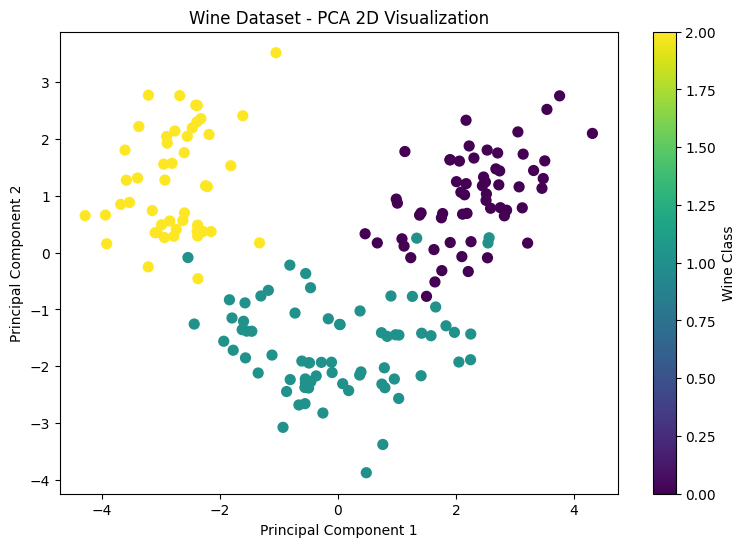

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

plt.scatter(
    X_2d[:, 0],
    X_2d[:, 1],
    c=y,
    cmap='viridis',
    s=50
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('Wine Dataset - PCA 2D Visualization')
plt.colorbar(label='Wine Class')

plt.show()

In [ ]:
from sklearn.cluster import KMeans

# Model on original scaled data
kmeans_original = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_original = kmeans_original.fit_predict(X_scaled)


# Model on PCA-reduced data
pca = PCA(n_components=0.80)
X_reduced = pca.fit_transform(X_scaled)

kmeans_pca = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

labels_pca = kmeans_pca.fit_predict(X_reduced)

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Original data
sil_original = silhouette_score(X_scaled, labels_original)
db_original = davies_bouldin_score(X_scaled, labels_original)

# PCA data
sil_pca = silhouette_score(X_reduced, labels_pca)
db_pca = davies_bouldin_score(X_reduced, labels_pca)

print("Original Data")
print("Silhouette:", round(sil_original, 3))
print("Davies-Bouldin:", round(db_original, 3))

print("\nPCA Reduced Data")
print("Silhouette:", round(sil_pca, 3))
print("Davies-Bouldin:", round(db_pca, 3))

Original Data
Silhouette: 0.285
Davies-Bouldin: 1.389

PCA Reduced Data
Silhouette: 0.369
Davies-Bouldin: 1.093


In [ ]:
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error

# Reduce to 5 components
pca = PCA(n_components=5)
X_reduced = pca.fit_transform(X_scaled)

# Reconstruct original feature space
X_reconstructed = pca.inverse_transform(X_reduced)

# Calculate reconstruction error
error = mean_squared_error(X_scaled, X_reconstructed)

print("Reconstruction Error:", error)

Reconstruction Error: 0.19837707244452127


In [ ]:
components = [2, 3, 5, 8, 10, 13]
errors = []

for n in components:
    pca = PCA(n_components=n)
    X_reduced = pca.fit_transform(X_scaled)

    X_reconstructed = pca.inverse_transform(X_reduced)

    error = mean_squared_error(X_scaled, X_reconstructed)
    errors.append(error)

    print(f"Components: {n}, Error: {error:.4f}")

Components: 2, Error: 0.4459
Components: 3, Error: 0.3347
Components: 5, Error: 0.1984
Components: 8, Error: 0.0798
Components: 10, Error: 0.0383
Components: 13, Error: 0.0000
